#imports

In [2]:
pip install clip

  Preparing metadata (setup.py) ... done
  Created wheel for clip: filename=clip-0.2.0-py3-none-any.whl size=6989 sha256=feaedf0fb9fb7bf09e7ee212309c2aa91e70525a9de236fbd2b97941c30c99d0
  Stored in directory: /root/.cache/pip/wheels/ab/a5/e8/c9fa20742edbccf2702dae8ee62053e6c460e961d45967b49c
Successfully built clip


In [2]:
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-y_bmebq_
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-y_bmebq_
  Resolved https://github.com/openai/CLIP.git to commit dcba3cb2e2827b402d2701e7e1c7d9fed8a20ef1
  Preparing metadata (setup.py) ... done


In [3]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
import warnings
warnings.filterwarnings('ignore')
import copy
from PIL import Image
import tarfile
import os
import glob
import matplotlib.pyplot as plt
from torchvision import transforms
import random
import itertools
from copy import deepcopy
import zipfile
import torchvision.transforms as transforms
import torchvision.models as models
import clip

#A

## данные

Файл best_pictures.tar.gz успешно разархивирован в папку A


,input,output
0,"[[174, 160, 172, 198, 167, 159, 158, 157, 159,...","[324.81640625, 364.234375, 353.43359375, 333.4..."
1,"[[127, 129, 128, 127, 126, 129, 123, 93, 90, 7...","[214.46484375, 234.76171875, 223.7578125, 212...."
2,"[[195, 178, 163, 186, 196, 188, 166, 171, 202,...","[316.19140625, 357.00390625, 361.8515625, 366...."
3,"[[61, 47, 31, 24, 27, 31, 45, 116, 145, 153, 1...","[67.16796875, 75.69921875, 72.95703125, 70.371..."
4,"[[38, 33, 39, 33, 17, 17, 18, 15, 9, 13, 18, 1...","[69.8828125, 70.78125, 58.01171875, 45.4023437..."
...,...,...
995,"[[97, 112, 100, 98, 134, 116, 216, 175, 177, 1...","[170.11328125, 202.3046875, 216.80078125, 236...."
996,"[[106, 104, 107, 96, 92, 83, 85, 77, 79, 79, 8...","[180.01171875, 194.69921875, 178.44140625, 160..."
997,"[[28, 23, 18, 20, 21, 19, 18, 17, 15, 22, 25, ...","[33.421875, 37.22265625, 37.23828125, 37.98828..."
998,"[[88, 80, 75, 78, 81, 80, 79, 75, 78, 81, 83, ...","[153.3515625, 170.46875, 170.04296875, 172.558..."


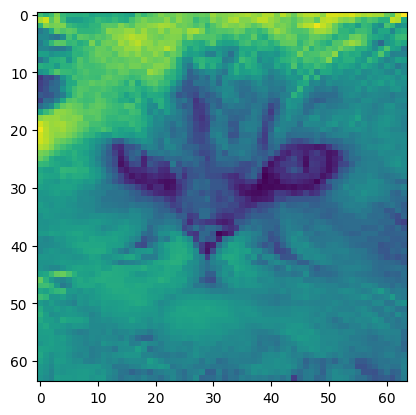

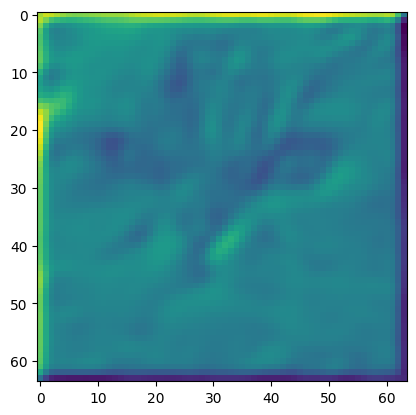

In [ ]:
cl1,cl2 = pd.read_csv('/content/algos.csv',header=None).iloc[0,:].values.reshape(3,3),pd.read_csv('/content/algos.csv',header=None).iloc[1,:].values.reshape(3,3)
cl2
# Пример: Представим, что у вас есть два фильтра 3x3 для обработки одноканальных изображений
# (например, grayscale).
# Замените это реальными значениями ваших фильтров!
# Преобразуем в тензоры PyTorch
filter1_tensor = torch.from_numpy(cl1)
filter2_tensor = torch.from_numpy(cl2)

# Формируем тензор весов в нужном формате (out_channels, in_channels, kernel_height, kernel_width)
filters_tensor = torch.stack([filter1_tensor, filter2_tensor]).unsqueeze(1)  # Добавляем in_channels=1

# Создаем сверточный слой
in_channels = 1 # Входные каналы
out_channels = 2 # Выходные каналы, т.е., количество фильтров
kernel_size = 3
conv_layer = nn.Conv2d(in_channels, out_channels, kernel_size, bias=False)  # bias=False, если вы не используете смещение

# Загружаем веса фильтров
conv_layer.weight = nn.Parameter(filters_tensor) # Присваиваем тензор весов параметру слоя

# Теперь у вас есть сверточный слой `conv_layer` с загруженными весами.



# 1. Разархивировать best_pictures.tar.gz в папку A

archive_file = "best_pictures.tar.gz"
extract_dir = "A"

# Создать папку A, если ее нет
if not os.path.exists(extract_dir):
    os.makedirs(extract_dir)

# Разархивировать
try:
    with tarfile.open(archive_file, "r:gz") as tar:
        tar.extractall(path=extract_dir)
    print(f"Файл {archive_file} успешно разархивирован в папку {extract_dir}")
except FileNotFoundError:
    print(f"Ошибка: Файл {archive_file} не найден.")
except Exception as e:
    print(f"Ошибка при разархивировании: {e}")
    exit()


# 2. Создать массивы с именами файлов .png и .txt из A

png_files = glob.glob(os.path.join(extract_dir, "*.png"))
txt_files = glob.glob(os.path.join(extract_dir, "*.txt"))

# 3. Сортировка файлов по числовому значению в имени

def extract_number(filename):
    try:
        base_name = os.path.basename(filename)  # Получаем имя файла без пути
        number_str = base_name.split('.')[0] # Получаем числовую часть имени файла
        return int(number_str)
    except ValueError:
        return float('inf')  # Если не удалось преобразовать в число, помещаем в конец списка

png_files.sort(key=extract_number)
txt_files.sort(key=extract_number)


# 4. Создать списки numpy массивов для png и txt

png_arrays = []
for png_file in png_files:
    try:
        img = Image.open(png_file)
        png_array = np.array(img)
        png_arrays.append(png_array)
    except Exception as e:
        print(f"Ошибка при чтении PNG файла {png_file}: {e}")
        png_arrays.append(None)  # или другое значение по умолчанию

txt_arrays = []
for txt_file in txt_files:
    try:
        with open(txt_file, 'r') as f:
            text_content = f.read()
            # Разбить строку на числа и создать numpy array
            numbers = [float(x) for x in text_content.split()]
            txt_array = np.array(numbers)
            txt_arrays.append(txt_array)
    except Exception as e:
        print(f"Ошибка при чтении TXT файла {txt_file}: {e}")
        txt_arrays.append(None) # или другое значение по умолчанию


# 5. Сделать Pandas DataFrame

# Определите минимальную длину списков, чтобы избежать ошибки при создании DataFrame
min_len = min(len(png_arrays), len(txt_arrays))

# Обрежьте списки до этой длины
png_arrays = png_arrays[:min_len]
txt_arrays = txt_arrays[:min_len]


df = pd.DataFrame({"input": png_arrays, "output": txt_arrays})

# Удалите строки, где есть None в input или output
df = df.dropna()


# Вывести DataFrame
display(df)

plt.imshow(df.iloc[0,0].reshape(64,64));plt.show()
plt.imshow(df.iloc[0,1].reshape(64,64));plt.show()


# Предполагаем, что ваши данные уже приведены к одному размеру и формату

# 6. Разделение на обучающую и тестовую выборки

X = df['input'].values
y = df['output'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # stratify=y если классы несбалансированны

# 7. Создание Dataset и DataLoader

class CustomDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]

        # Преобразуем numpy массивы в тензоры PyTorch
        image = torch.from_numpy(image).double()
        label = torch.from_numpy(label).double()

        # Добавляем размерность канала, если изображение одноканальное (grayscale)
        if len(image.shape) == 2:
            image = image.unsqueeze(0) # C H W
        elif len(image.shape) == 3:
            image = image.permute(2, 0, 1) # H W C -> C H W

        # Применяем трансформации, если они есть
        if self.transform:
            image = self.transform(image)

        return image, label

'''
# Определите трансформации, если необходимо (например, нормализация)
transform = transforms.Compose([
    #transforms.ToTensor(), # Преобразование в тензор (можно не использовать, если уже преобразовано)
    transforms.Normalize((0.5,), (0.5,)) # Пример: Нормализация для grayscale изображений
])

train_dataset = CustomDataset(X_train, y_train, transform=transform)
test_dataset = CustomDataset(X_test, y_test, transform=transform)
'''
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Размеры пакета изображений: torch.Size([32, 1, 64, 64])
Размеры пакета меток: torch.Size([32, 4096])
Размер одного изображения: torch.Size([1, 64, 64])
Минимальное значение пикселей: 18.0
Максимальное значение пикселей: 231.0


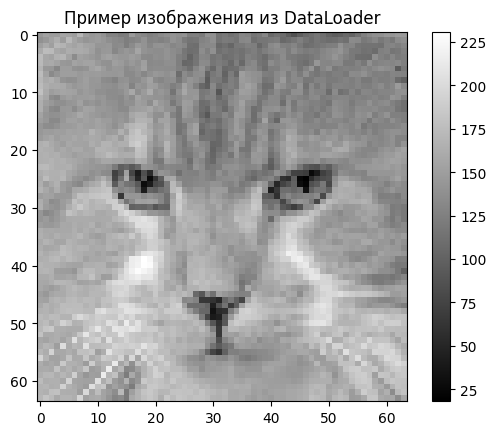

In [ ]:

# Получаем один пакет данных из train_loader
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Выводим размеры полученного пакета
print("Размеры пакета изображений:", images.shape)
print("Размеры пакета меток:", labels.shape)

# Выводим одно изображение из пакета
image = images[0]  # Берем первое изображение из пакета
print("Размер одного изображения:", image.shape)

# Удаляем размерность канала, если изображение одноканальное
if len(image.shape) == 3 and image.shape[0] == 1:
    image = image.squeeze(0)

# Переносим изображение на CPU, если оно находится на GPU
image = image.cpu()

# Преобразуем тензор в numpy массив
image_numpy = image.detach().numpy()  # Отсоединяем от графа вычислений

# Выводим минимальное и максимальное значение пикселей
print("Минимальное значение пикселей:", image_numpy.min())
print("Максимальное значение пикселей:", image_numpy.max())

# Визуализируем изображение
plt.imshow(image_numpy, cmap='gray')  # Используйте 'gray' для одноканальных изображений
plt.title("Пример изображения из DataLoader")
plt.colorbar()  # Добавляем цветовую шкалу для интерпретации значений
plt.show()

## сеть

In [ ]:
# Загрузка фильтров
cl1,cl2 = pd.read_csv('/content/algos.csv',header=None).iloc[0,:].values.reshape(3,3),pd.read_csv('/content/algos.csv',header=None).iloc[1,:].values.reshape(3,3)
# Преобразуем в тензоры PyTorch
filter1_tensor = torch.from_numpy(cl1).float()
filter2_tensor = torch.from_numpy(cl2).float()
# Формируем тензор весов в нужном формате (out_channels, in_channels, kernel_height, kernel_width)
filters_tensor1 = torch.stack([filter1_tensor]).unsqueeze(0)  # Добавляем in_channels=1, out_channels=1
filters_tensor2 = torch.stack([filter2_tensor]).unsqueeze(0)  # Добавляем in_channels=1, out_channels=1
# Создаем сверточные слои
in_channels = 1 # Входные каналы
out_channels1 = 1  # Выходные каналы, т.е., количество фильтров
out_channels2 = 1
kernel_size = 3
conv_layer1 = nn.Conv2d(in_channels, out_channels1, kernel_size, bias=False,padding=1)  # bias=False, если вы не используете смещение
conv_layer2 = nn.Conv2d(out_channels1, out_channels2, kernel_size, bias=False,padding=1)
# Загружаем веса фильтров
conv_layer1.weight = nn.Parameter(filters_tensor1) # Присваиваем тензор весов параметру слоя
conv_layer2.weight = nn.Parameter(filters_tensor2)
conv_layer1.weight.requires_grad = False
conv_layer2.weight.requires_grad = False


seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False





# Создаем модель
model = nn.Sequential(
    conv_layer1,  # Первый сверточный слой с заданными весами
    nn.ReLU(),
    conv_layer2,  # Второй сверточный слой с заданными весами
    nn.ReLU(),
    nn.Conv2d(1,1,3,padding=1),
    nn.Flatten()
)







criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 100
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)





all_layers = [
    ("cl1", conv_layer1),
    ("cl2", conv_layer2),
    ("c3", nn.Conv2d(1,1,3,padding=1))
]


permuts = list(itertools.permutations(all_layers, 3))

results = []

for idx, layer_order in enumerate(permuts):
    print(f"\n=== Вариант {idx+1}: {[name for name, _ in layer_order]} ===")

    layers = []
    for i,(name, layer) in enumerate(layer_order):
        layers.append(deepcopy(layer))  # важно: без deepcopy PyTorch переиспользует веса
        if i < 2:  # Только между слоями
          layers.append(nn.ReLU())

    layers.append(nn.Flatten())
    model = nn.Sequential(*layers).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    for epoch in range(num_epochs):
        running_loss = 0.0
        for i, (inputs, labels) in enumerate(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"  Эпоха {epoch+1}, Loss: {running_loss / len(train_loader)}")

    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

    print(f"  Test Loss: {test_loss / len(test_loader)}")
    results.append((layer_order, test_loss / len(test_loader)))





# Сортируем по test loss и берём лучший
best_layers, _ = sorted(results, key=lambda x: x[1])[0]

# Восстанавливаем фильтры в порядке применения
final_filters = []
for name, layer in best_layers:
    filt = layer.weight.detach().cpu().numpy().reshape(9,)
    final_filters.append(filt)

# Сохраняем в CSV
final_df = pd.DataFrame(final_filters)
final_df.to_csv("reconstructed_algos.csv", index=False, header=False)
print("\nФильтры сохранены в reconstructed_algos.csv")




=== Вариант 1: ['cl1', 'cl2', 'c3'] ===


RuntimeError: Input type (torch.cuda.DoubleTensor) and weight type (torch.cuda.FloatTensor) should be the same

##best only

In [ ]:

# Загрузка фильтров
cl1,cl2 = pd.read_csv('/content/algos.csv',header=None).iloc[0,:].values.reshape(3,3),pd.read_csv('/content/algos.csv',header=None).iloc[1,:].values.reshape(3,3)
# Преобразуем в тензоры PyTorch
filter1_tensor = torch.from_numpy(cl1).float()
filter2_tensor = torch.from_numpy(cl2).float()
# Формируем тензор весов в нужном формате (out_channels, in_channels, kernel_height, kernel_width)
filters_tensor1 = torch.stack([filter1_tensor]).unsqueeze(0).double()  # Добавляем in_channels=1, out_channels=1
filters_tensor2 = torch.stack([filter2_tensor]).unsqueeze(0).double()  # Добавляем in_channels=1, out_channels=1
# Создаем сверточные слои
in_channels = 1 # Входные каналы
out_channels1 = 1  # Выходные каналы, т.е., количество фильтров
out_channels2 = 1
kernel_size = 3
conv_layer1 = nn.Conv2d(in_channels, out_channels1, kernel_size, bias=False,padding=1).double()  # bias=False, если вы не используете смещение
conv_layer2 = nn.Conv2d(out_channels1, out_channels2, kernel_size, bias=False,padding=1).double()
# Загружаем веса фильтров
conv_layer1.weight = nn.Parameter(filters_tensor1) # Присваиваем тензор весов параметру слоя
conv_layer2.weight = nn.Parameter(filters_tensor2)
conv_layer1.weight.requires_grad = False
conv_layer2.weight.requires_grad = False


seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False





# Создаем модель
model = nn.Sequential(
    conv_layer1,  # Первый сверточный слой с заданными весами
    nn.ReLU(),
    conv_layer2,  # Второй сверточный слой с заданными весами
    nn.ReLU(),
    nn.Conv2d(1,1,3,padding=1),
    nn.Flatten()
)







criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 350
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)




#=== Вариант 4: ['cl2', 'c3', 'cl1'] ===
#=== Вариант 6: ['c3', 'cl2', 'cl1'] ===

all_layers1 = [
    ("cl2", conv_layer2),
    ("c3", nn.Conv2d(1,1,3,padding=1)),
    ("cl1", conv_layer1)
]
all_layers2 = [
    ("c3", nn.Conv2d(1,1,3,padding=1)),
    ("cl2", conv_layer2),
    ("cl1", conv_layer1)
]


permuts = [all_layers1]

results = []

for idx, layer_order in enumerate(permuts):
    print(f"\n=== Вариант {idx+1}: {[name for name, _ in layer_order]} ===")

    layers = []
    for i,(name, layer) in enumerate(layer_order):
        layers.append(deepcopy(layer))  # важно: без deepcopy PyTorch переиспользует веса
        #if i < 2:  # Только между слоями
        #  layers.append(nn.ReLU())

    layers.append(nn.Flatten())
    model = nn.Sequential(*layers).double().to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

    for epoch in range(num_epochs):
        running_loss = 0.0
        for i, (inputs, labels) in enumerate(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"  Эпоха {epoch+1}, Loss: {running_loss / len(train_loader)}")

    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

    print(f"  Test Loss: {test_loss / len(test_loader)}")
    results.append((layer_order, test_loss / len(test_loader)))





# Сортируем по test loss и берём лучший
best_layers, _ = sorted(results, key=lambda x: x[1])[0]

# Восстанавливаем фильтры в порядке применения
final_filters = []
for name, layer in best_layers:
    filt = layer.weight.detach().cpu().numpy().reshape(9,)
    final_filters.append(filt)

# Сохраняем в CSV
final_df = pd.DataFrame(final_filters)
final_df.to_csv("reconstructed_algos.csv", index=False, header=False)
print("\nФильтры сохранены в reconstructed_algos.csv")




=== Вариант 1: ['cl2', 'c3', 'cl1'] ===
  Эпоха 1, Loss: 423.37002732744537
  Эпоха 2, Loss: 36.526714505356566
  Эпоха 3, Loss: 7.8883019550757805
  Эпоха 4, Loss: 2.5782564225998748
  Эпоха 5, Loss: 1.147438951381058
  Эпоха 6, Loss: 0.5381698052071259
  Эпоха 7, Loss: 0.2772131617191432
  Эпоха 8, Loss: 0.16992563070983496
  Эпоха 9, Loss: 0.1231563378543468
  Эпоха 10, Loss: 0.09794190618997285
  Эпоха 11, Loss: 0.08070239601493079
  Эпоха 12, Loss: 0.06683698276761108
  Эпоха 13, Loss: 0.055276427311643686
  Эпоха 14, Loss: 0.04542165162982456
  Эпоха 15, Loss: 0.03731032460068006
  Эпоха 16, Loss: 0.03040020989631661
  Эпоха 17, Loss: 0.02477591167048267
  Эпоха 18, Loss: 0.020172639590499704
  Эпоха 19, Loss: 0.016532907967970835
  Эпоха 20, Loss: 0.013559964325668354
  Эпоха 21, Loss: 0.011185318016306185
  Эпоха 22, Loss: 0.009333639665952125
  Эпоха 23, Loss: 0.007864344291356405
  Эпоха 24, Loss: 0.006725353831588007
  Эпоха 25, Loss: 0.005826892662410255
  Эпоха 26, Loss: 

In [ ]:
print(conv_layer1.weight.dtype)  # Должно вывести torch.float64
print(cl1,'\n',cl2)

torch.float64
[[-1.  -0.5  0. ]
 [-0.5  0.5  0.5]
 [ 0.   0.5  1. ]] 
 [[0.0625 0.0625 0.0625]
 [0.0625 0.0625 0.0625]
 [0.0625 0.0625 0.0625]]


##A ver2

Файл best_pictures.tar.gz успешно разархивирован в папку A


,input,output
0,"[[174, 160, 172, 198, 167, 159, 158, 157, 159,...","[324.81640625, 364.234375, 353.43359375, 333.4..."
1,"[[127, 129, 128, 127, 126, 129, 123, 93, 90, 7...","[214.46484375, 234.76171875, 223.7578125, 212...."
2,"[[195, 178, 163, 186, 196, 188, 166, 171, 202,...","[316.19140625, 357.00390625, 361.8515625, 366...."
3,"[[61, 47, 31, 24, 27, 31, 45, 116, 145, 153, 1...","[67.16796875, 75.69921875, 72.95703125, 70.371..."
4,"[[38, 33, 39, 33, 17, 17, 18, 15, 9, 13, 18, 1...","[69.8828125, 70.78125, 58.01171875, 45.4023437..."
...,...,...
995,"[[97, 112, 100, 98, 134, 116, 216, 175, 177, 1...","[170.11328125, 202.3046875, 216.80078125, 236...."
996,"[[106, 104, 107, 96, 92, 83, 85, 77, 79, 79, 8...","[180.01171875, 194.69921875, 178.44140625, 160..."
997,"[[28, 23, 18, 20, 21, 19, 18, 17, 15, 22, 25, ...","[33.421875, 37.22265625, 37.23828125, 37.98828..."
998,"[[88, 80, 75, 78, 81, 80, 79, 75, 78, 81, 83, ...","[153.3515625, 170.46875, 170.04296875, 172.558..."


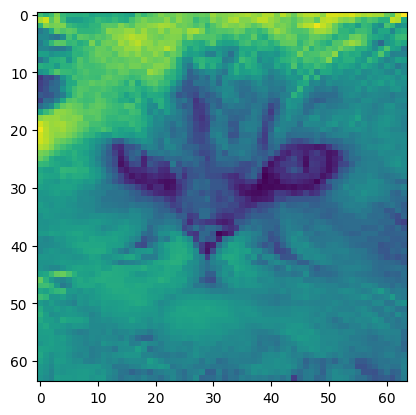

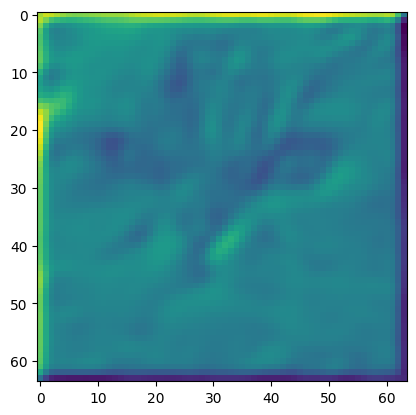

In [ ]:
# 1. Разархивировать best_pictures.tar.gz в папку A

archive_file = "best_pictures.tar.gz"
extract_dir = "A"

# Создать папку A, если ее нет
if not os.path.exists(extract_dir):
    os.makedirs(extract_dir)

# Разархивировать
try:
    with tarfile.open(archive_file, "r:gz") as tar:
        tar.extractall(path=extract_dir)
    print(f"Файл {archive_file} успешно разархивирован в папку {extract_dir}")
except FileNotFoundError:
    print(f"Ошибка: Файл {archive_file} не найден.")
except Exception as e:
    print(f"Ошибка при разархивировании: {e}")
    exit()


# 2. Создать массивы с именами файлов .png и .txt из A

png_files = glob.glob(os.path.join(extract_dir, "*.png"))
txt_files = glob.glob(os.path.join(extract_dir, "*.txt"))

# 3. Сортировка файлов по числовому значению в имени

def extract_number(filename):
    try:
        base_name = os.path.basename(filename)  # Получаем имя файла без пути
        number_str = base_name.split('.')[0] # Получаем числовую часть имени файла
        return int(number_str)
    except ValueError:
        return float('inf')  # Если не удалось преобразовать в число, помещаем в конец списка

png_files.sort(key=extract_number)
txt_files.sort(key=extract_number)


# 4. Создать списки numpy массивов для png и txt

png_arrays = []
for png_file in png_files:
    try:
        img = Image.open(png_file)
        png_array = np.array(img)
        png_arrays.append(png_array)
    except Exception as e:
        print(f"Ошибка при чтении PNG файла {png_file}: {e}")
        png_arrays.append(None)  # или другое значение по умолчанию

txt_arrays = []
for txt_file in txt_files:
    try:
        with open(txt_file, 'r') as f:
            text_content = f.read()
            # Разбить строку на числа и создать numpy array
            numbers = [float(x) for x in text_content.split()]
            txt_array = np.array(numbers)
            txt_arrays.append(txt_array)
    except Exception as e:
        print(f"Ошибка при чтении TXT файла {txt_file}: {e}")
        txt_arrays.append(None) # или другое значение по умолчанию


# 5. Сделать Pandas DataFrame

# Определите минимальную длину списков, чтобы избежать ошибки при создании DataFrame
min_len = min(len(png_arrays), len(txt_arrays))

# Обрежьте списки до этой длины
png_arrays = png_arrays[:min_len]
txt_arrays = txt_arrays[:min_len]


df = pd.DataFrame({"input": png_arrays, "output": txt_arrays})

# Удалите строки, где есть None в input или output
df = df.dropna()


# Вывести DataFrame
display(df)

plt.imshow(df.iloc[0,0].reshape(64,64));plt.show()
plt.imshow(df.iloc[0,1].reshape(64,64));plt.show()


# Предполагаем, что ваши данные уже приведены к одному размеру и формату

# 6. Разделение на обучающую и тестовую выборки

X = df['input'].values
y = df['output'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # stratify=y если классы несбалансированны

# 7. Создание Dataset и DataLoader

class CustomDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]

        # Преобразуем numpy массивы в тензоры PyTorch
        image = torch.from_numpy(image).double()
        label = torch.from_numpy(label).double()
        '''
        # Добавляем размерность канала, если изображение одноканальное (grayscale)
        if len(image.shape) == 2:
            image = image.unsqueeze(0) # C H W
        elif len(image.shape) == 3:
            image = image.permute(2, 0, 1) # H W C -> C H W
        '''
        # Применяем трансформации, если они есть
        if self.transform:
            image = self.transform(image)

        return image, label

'''
# Определите трансформации, если необходимо (например, нормализация)
transform = transforms.Compose([
    #transforms.ToTensor(), # Преобразование в тензор (можно не использовать, если уже преобразовано)
    transforms.Normalize((0.5,), (0.5,)) # Пример: Нормализация для grayscale изображений
])

train_dataset = CustomDataset(X_train, y_train, transform=transform)
test_dataset = CustomDataset(X_test, y_test, transform=transform)
'''
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:

# Загрузка фильтров
cl1,cl2 = pd.read_csv('/content/algos.csv',header=None).iloc[0,:].values.reshape(3,3),pd.read_csv('/content/algos.csv',header=None).iloc[1,:].values.reshape(3,3)
# Преобразуем в тензоры PyTorch
filter1_tensor = torch.from_numpy(cl1).float()
filter2_tensor = torch.from_numpy(cl2).float()
# Формируем тензор весов в нужном формате (out_channels, in_channels, kernel_height, kernel_width)
filters_tensor1 = torch.stack([filter1_tensor]).double()  # Добавляем in_channels=1, out_channels=1
filters_tensor2 = torch.stack([filter2_tensor]).double()  # Добавляем in_channels=1, out_channels=1
# Создаем сверточные слои
in_channels = 1 # Входные каналы
out_channels1 = 1  # Выходные каналы, т.е., количество фильтров
out_channels2 = 1
kernel_size = 3
conv_layer1 = nn.Conv2d(in_channels, out_channels1, kernel_size, bias=False,padding=1).double()  # bias=False, если вы не используете смещение
conv_layer2 = nn.Conv2d(out_channels1, out_channels2, kernel_size, bias=False,padding=1).double()
# Загружаем веса фильтров
conv_layer1.weight = nn.Parameter(filters_tensor1) # Присваиваем тензор весов параметру слоя
conv_layer2.weight = nn.Parameter(filters_tensor2)
conv_layer1.weight.requires_grad = False
conv_layer2.weight.requires_grad = False


seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False






criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 1500
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)




#=== Вариант 4: ['cl2', 'c3', 'cl1'] ===
#=== Вариант 6: ['c3', 'cl2', 'cl1'] ===

all_layers1 = [
    ("cl2", conv_layer2),
    ("c3", nn.Conv2d(1,1,3,padding=1)),
    ("cl1", conv_layer1)
]
all_layers2 = [
    ("c3", nn.Conv2d(1,1,3,padding=1)),
    ("cl2", conv_layer2),
    ("cl1", conv_layer1)
]


permuts = [all_layers2]

results = []

for idx, layer_order in enumerate(permuts):
    print(f"\n=== Вариант {idx+1}: {[name for name, _ in layer_order]} ===")

    layers = []
    for i,(name, layer) in enumerate(layer_order):
        layers.append(deepcopy(layer))  # важно: без deepcopy PyTorch переиспользует веса
        if i < 2:  # Только между слоями
          layers.append(nn.ReLU())

    layers.append(nn.Flatten())
    model = nn.Sequential(*layers).double().to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(num_epochs):
        running_loss = 0.0
        for i, (inputs, labels) in enumerate(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        print(f"  Эпоха {epoch+1}, Loss: {running_loss / len(train_loader)}")

    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

    print(f"  Test Loss: {test_loss / len(test_loader)}")
    results.append((layer_order, test_loss / len(test_loader)))





# Сортируем по test loss и берём лучший
best_layers, _ = sorted(results, key=lambda x: x[1])[0]

# Восстанавливаем фильтры в порядке применения
final_filters = []
for name, layer in best_layers:
    filt = layer.weight.detach().cpu().numpy().reshape(9,)
    final_filters.append(filt)

# Сохраняем в CSV
final_df = pd.DataFrame(final_filters)
final_df.to_csv("reconstructed_algos.csv", index=False, header=False)
print("\nФильтры сохранены в reconstructed_algos.csv")




=== Вариант 1: ['c3', 'cl2', 'cl1'] ===


RuntimeError: Given groups=1, weight of size [1, 1, 3, 3], expected input[1, 32, 64, 64] to have 1 channels, but got 32 channels instead

##A ver3

In [ ]:
# Загрузка фильтров
cl1,cl2 = pd.read_csv('/content/algos.csv',header=None).iloc[0,:].values.reshape(3,3),pd.read_csv('/content/algos.csv',header=None).iloc[1,:].values.reshape(3,3)
# Преобразуем в тензоры PyTorch
filter1_tensor = torch.from_numpy(cl1).float()
filter2_tensor = torch.from_numpy(cl2).float()
# Формируем тензор весов в нужном формате (out_channels, in_channels, kernel_height, kernel_width)
filters_tensor1 = torch.stack([filter1_tensor]).unsqueeze(0).double()  # Добавляем in_channels=1, out_channels=1
filters_tensor2 = torch.stack([filter2_tensor]).unsqueeze(0).double()  # Добавляем in_channels=1, out_channels=1
# Создаем сверточные слои
in_channels = 1 # Входные каналы
out_channels1 = 1  # Выходные каналы, т.е., количество фильтров
out_channels2 = 1
kernel_size = 3
conv_layer1 = nn.Conv2d(in_channels, out_channels1, kernel_size, bias=False,padding=1).double()  # bias=False, если вы не используете смещение
conv_layer2 = nn.Conv2d(out_channels1, out_channels2, kernel_size, bias=False,padding=1).double()
# Загружаем веса фильтров
conv_layer1.weight = nn.Parameter(filters_tensor1) # Присваиваем тензор весов параметру слоя
conv_layer2.weight = nn.Parameter(filters_tensor2)
conv_layer1.weight.requires_grad = False
conv_layer2.weight.requires_grad = False


seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


criterion = nn.MSELoss()

num_epochs = 1500
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
class ThreeConvModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = conv_layer2
        self.conv2 = nn.Conv2d(1, 1, 3, padding=1, bias=False).double()
        self.conv3 = conv_layer1
    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        return x

model = ThreeConvModel().to(device)
model.to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


# 1. Разархивировать best_pictures.tar.gz в папку A

archive_file = "best_pictures.tar.gz"
extract_dir = "A"

# Создать папку A, если ее нет
if not os.path.exists(extract_dir):
    os.makedirs(extract_dir)

# Разархивировать
try:
    with tarfile.open(archive_file, "r:gz") as tar:
        tar.extractall(path=extract_dir)
    print(f"Файл {archive_file} успешно разархивирован в папку {extract_dir}")
except FileNotFoundError:
    print(f"Ошибка: Файл {archive_file} не найден.")
except Exception as e:
    print(f"Ошибка при разархивировании: {e}")
    exit()


# 2. Создать массивы с именами файлов .png и .txt из A

png_files = glob.glob(os.path.join(extract_dir, "*.png"))
txt_files = glob.glob(os.path.join(extract_dir, "*.txt"))

# 3. Сортировка файлов по числовому значению в имени

def extract_number(filename):
    try:
        base_name = os.path.basename(filename)  # Получаем имя файла без пути
        number_str = base_name.split('.')[0] # Получаем числовую часть имени файла
        return int(number_str)
    except ValueError:
        return float('inf')  # Если не удалось преобразовать в число, помещаем в конец списка

png_files.sort(key=extract_number)
txt_files.sort(key=extract_number)


# 4. Создать списки numpy массивов для png и txt

png_arrays = []
for png_file in png_files:
    try:
        img = Image.open(png_file)
        png_array = np.array(img)
        png_arrays.append(png_array)
    except Exception as e:
        print(f"Ошибка при чтении PNG файла {png_file}: {e}")
        png_arrays.append(None)  # или другое значение по умолчанию

txt_arrays = []
for txt_file in txt_files:
    try:
        with open(txt_file, 'r') as f:
            text_content = f.read()
            # Разбить строку на числа и создать numpy array
            numbers = [float(x) for x in text_content.split()]
            txt_array = np.array(numbers)
            txt_arrays.append(txt_array)
    except Exception as e:
        print(f"Ошибка при чтении TXT файла {txt_file}: {e}")
        txt_arrays.append(None) # или другое значение по умолчанию


# 5. Сделать Pandas DataFrame

# Определите минимальную длину списков, чтобы избежать ошибки при создании DataFrame
min_len = min(len(png_arrays), len(txt_arrays))

# Обрежьте списки до этой длины
png_arrays = png_arrays[:min_len]
txt_arrays = txt_arrays[:min_len]


df = pd.DataFrame({"input": png_arrays, "output": txt_arrays})

img=df.iloc[0,0].reshape(64,64)
target=df.iloc[0,1].reshape(64,64)

for epoch in range(10000):
    optimizer.zero_grad()
    output = model(img)
    loss = criterion(output, target)
    loss.backward()
    optimizer.step()



# Восстанавливаем фильтры в порядке применения
final_filters = []
for name, layer in best_layers:
    filt = layer.weight.detach().cpu().numpy().reshape(9,)
    final_filters.append(filt)

# Сохраняем в CSV
final_df = pd.DataFrame(final_filters)
final_df.to_csv("reconstructed_algos.csv", index=False, header=False)
print("\nФильтры сохранены в reconstructed_algos.csv")


Файл best_pictures.tar.gz успешно разархивирован в папку A


TypeError: conv2d() received an invalid combination of arguments - got (numpy.ndarray, Parameter, NoneType, tuple, tuple, tuple, int), but expected one of:
 * (Tensor input, Tensor weight, Tensor bias = None, tuple of ints stride = 1, tuple of ints padding = 0, tuple of ints dilation = 1, int groups = 1)
      didn't match because some of the arguments have invalid types: (!numpy.ndarray!, !Parameter!, !NoneType!, !tuple of (int, int)!, !tuple of (int, int)!, !tuple of (int, int)!, !int!)
 * (Tensor input, Tensor weight, Tensor bias = None, tuple of ints stride = 1, str padding = "valid", tuple of ints dilation = 1, int groups = 1)
      didn't match because some of the arguments have invalid types: (!numpy.ndarray!, !Parameter!, !NoneType!, !tuple of (int, int)!, !tuple of (int, int)!, !tuple of (int, int)!, !int!)


In [ ]:

# 1. Разархивировать best_pictures.tar.gz в папку A

archive_file = "best_pictures.tar.gz"
extract_dir = "A"

# Создать папку A, если ее нет
if not os.path.exists(extract_dir):
    os.makedirs(extract_dir)

# Разархивировать
try:
    with tarfile.open(archive_file, "r:gz") as tar:
        tar.extractall(path=extract_dir)
    print(f"Файл {archive_file} успешно разархивирован в папку {extract_dir}")
except FileNotFoundError:
    print(f"Ошибка: Файл {archive_file} не найден.")
except Exception as e:
    print(f"Ошибка при разархивировании: {e}")
    exit()


# 2. Создать массивы с именами файлов .png и .txt из A

png_files = glob.glob(os.path.join(extract_dir, "*.png"))
txt_files = glob.glob(os.path.join(extract_dir, "*.txt"))

# 3. Сортировка файлов по числовому значению в имени

def extract_number(filename):
    try:
        base_name = os.path.basename(filename)  # Получаем имя файла без пути
        number_str = base_name.split('.')[0] # Получаем числовую часть имени файла
        return int(number_str)
    except ValueError:
        return float('inf')  # Если не удалось преобразовать в число, помещаем в конец списка

png_files.sort(key=extract_number)
txt_files.sort(key=extract_number)


# 4. Создать списки numpy массивов для png и txt

png_arrays = []
for png_file in png_files:
    try:
        img = Image.open(png_file)
        png_array = np.array(img)
        png_arrays.append(png_array)
    except Exception as e:
        print(f"Ошибка при чтении PNG файла {png_file}: {e}")
        png_arrays.append(None)  # или другое значение по умолчанию

txt_arrays = []
for txt_file in txt_files:
    try:
        with open(txt_file, 'r') as f:
            text_content = f.read()
            # Разбить строку на числа и создать numpy array
            numbers = [float(x) for x in text_content.split()]
            txt_array = np.array(numbers)
            txt_arrays.append(txt_array)
    except Exception as e:
        print(f"Ошибка при чтении TXT файла {txt_file}: {e}")
        txt_arrays.append(None) # или другое значение по умолчанию


# 5. Сделать Pandas DataFrame

# Определите минимальную длину списков, чтобы избежать ошибки при создании DataFrame
min_len = min(len(png_arrays), len(txt_arrays))

# Обрежьте списки до этой длины
png_arrays = png_arrays[:min_len]
txt_arrays = txt_arrays[:min_len]


df = pd.DataFrame({"input": png_arrays, "output": txt_arrays})

Файл best_pictures.tar.gz успешно разархивирован в папку A


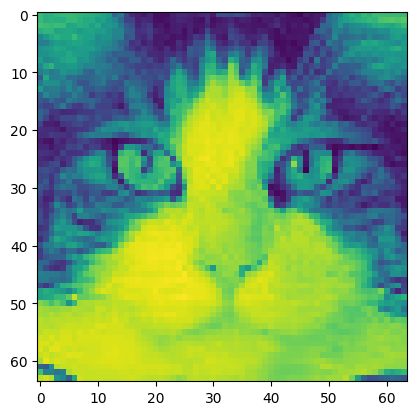


Final MSE: 0.000000
[[0.12499969 0.25000047 0.12499974]
 [0.25000046 0.49999903 0.25000046]
 [0.12499975 0.25000046 0.1249997 ]]

Фильтры сохранены в reconstructed_algos.csv


In [ ]:
import tarfile
import os
import glob
import pandas as pd
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
import random

# Загрузка фильтров
cl1,cl2 = pd.read_csv('/content/algos.csv',header=None).iloc[0,:].values.reshape(3,3),pd.read_csv('/content/algos.csv',header=None).iloc[1,:].values.reshape(3,3)
# Преобразуем в тензоры PyTorch
filter1_tensor = torch.from_numpy(cl1).float().double() #.double()
filter2_tensor = torch.from_numpy(cl2).float().double() #.double()
# Формируем тензор весов в нужном формате (out_channels, in_channels, kernel_height, kernel_width)
filters_tensor1 = torch.stack([filter1_tensor]).unsqueeze(0).double() #.double()
filters_tensor2 = torch.stack([filter2_tensor]).unsqueeze(0).double() #.double()
# Создаем сверточные слои
in_channels = 1 # Входные каналы
out_channels1 = 1  # Выходные каналы, т.е., количество фильтров
out_channels2 = 1
kernel_size = 3
conv_layer1 = nn.Conv2d(in_channels, out_channels1, kernel_size, bias=False,padding=1).double()
conv_layer2 = nn.Conv2d(out_channels1, out_channels2, kernel_size, bias=False,padding=1).double()
# Загружаем веса фильтров
conv_layer1.weight = nn.Parameter(filters_tensor1) # Присваиваем тензор весов параметру слоя
conv_layer2.weight = nn.Parameter(filters_tensor2)
conv_layer1.weight.requires_grad = False
conv_layer2.weight.requires_grad = False

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


criterion = nn.MSELoss()

num_epochs = 20000
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
class ThreeConvModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = conv_layer2
        self.conv2 = nn.Conv2d(1, 1, 3, padding=1, bias=False).double()
        self.conv3 = conv_layer1
    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        return x

model = ThreeConvModel().to(device)
#model.to(device)
optimizer = torch.optim.Adam([model.conv2.weight], lr=0.3)


model = model.double()
plt.imshow(df.iloc[776,0].reshape(64,64));plt.show()
img = torch.from_numpy(df.iloc[776,0].reshape(64,64)).unsqueeze(0).unsqueeze(0).double().to(device)
target = torch.from_numpy(df.iloc[776,1].reshape(64,64)).unsqueeze(0).unsqueeze(0).double().to(device)
for epoch in range(num_epochs):
    optimizer.zero_grad()
    output = model(img)
    loss = criterion(output, target)
    loss.backward()
    optimizer.step()
with torch.no_grad():
    full_output = model(img)
    ans = full_output.squeeze().cpu().numpy()
    # np.savetxt("output_matrix.txt", full_output.squeeze().cpu().numpy(), fmt="%.4f")
    final_mse = criterion(full_output, target).item()
    print(f"\nFinal MSE: {final_mse:.6f}")

# Определяем best_layers после обучения
best_layers = [("conv2", model.conv1), ("conv3", model.conv2), ("conv1", model.conv3)] # Задаем в том порядке, в котором они используются в модели

# Восстанавливаем фильтры в порядке применения
final_filters = []
for name, layer in best_layers:
    filt = layer.weight.detach().cpu().numpy().reshape(9,)
    final_filters.append(filt)

# Сохраняем в CSV
ku = model.conv2.weight.data.squeeze().cpu().numpy()
print(ku)
final_df = pd.DataFrame(final_filters)
final_df.to_csv("reconstructed_algos.csv", index=False, header=False)
print("\nФильтры сохранены в reconstructed_algos.csv")

In [ ]:
ku = model.conv1.weight.data.squeeze().cpu().numpy()
print(ku)
ku = model.conv3.weight.data.squeeze().cpu().numpy()
print(ku)

[[0.0625 0.0625 0.0625]
 [0.0625 0.0625 0.0625]
 [0.0625 0.0625 0.0625]]
[[-1.  -0.5  0. ]
 [-0.5  0.5  0.5]
 [ 0.   0.5  1. ]]


#B

##данные

In [4]:

# 2.  Укажите путь к dataset.zip на вашем Google Drive.
#     Замените 'path/to/your/dataset.zip' на реальный путь!
zip_path = '/content/drive/MyDrive/dataset.zip'  # <-- ВАЖНО:  измените этот путь

# 3. Определите папку, куда нужно распаковать (если ее нет, создайте)
extract_path = '/content/data'
if not os.path.exists(extract_path):
    os.makedirs(extract_path)

# 4. Распаковываем zip-файл
try:
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Файл {zip_path} успешно распакован в {extract_path}")

except FileNotFoundError:
    print(f"Ошибка: Файл {zip_path} не найден.  Пожалуйста, проверьте путь к файлу.")
except zipfile.BadZipFile:
    print(f"Ошибка: Файл {zip_path} поврежден или не является допустимым zip-архивом.")
except Exception as e:
    print(f"Произошла ошибка при распаковке: {e}")


# Дополнительная проверка (необязательно):  Вывести список файлов в распакованной папке
print("\nСписок файлов в папке 'data':")
for filename in os.listdir(extract_path):
    print(filename)

#/content/data/dataset

Файл /content/drive/MyDrive/dataset.zip успешно распакован в /content/data

Список файлов в папке 'data':
dataset


##нн

In [5]:
#image_input = torch.tensor(np.stack(images)).cuda()
#image_features /= image_features.norm(dim=-1, keepdim = True)
#similarirty = text_features.cpu().numpy() @ image_features.cpu().numpy.T
'''
model,preprocess = clip.load("ViT-B/32")
model.cuda().eval()
input_resolution = model.visual.input_resolution
context_length = model.context_length
vocab_size = model.vocab_size
with torch.no_grad():
  image_features = model.encode_image(image_input).float()
'''

dataset_path = '/content/data/dataset'
images = []
for filename in os.listdir(dataset_path):
    if filename.endswith('.png'):
        img_path = os.path.join(dataset_path, filename)
        img = Image.open(img_path).convert('RGB')
        img_array = np.array(img)
        images.append(img_array)

image_input = torch.tensor(np.stack(images))#.cuda()

In [6]:
clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [ ]:
model,preprocess = clip.load("ViT-B/32")
#model.cuda().eval()
model.eval()

with torch.no_grad():
  image_features = model.encode_image(image_input).float()

similarirty = image_features.cpu().numpy() @ image_features.cpu().numpy.T